<a href="https://colab.research.google.com/github/ananyavj/DeepLearning/blob/main/Question%201/C_CIFAR10_FNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/DeepLearning/datasets"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv(f"{BASE}/FNN and CNN/CIFAR10/cifar-10.csv")
print("Shape:",df.shape)
print(df.columns.tolist()[:10], "...", df.columns.tolist()[-10:])
print(df.head(5))
print(sorted(df["label"].unique()))

Shape: (50000, 3073)
['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9'] ... ['pixel_3063', 'pixel_3064', 'pixel_3065', 'pixel_3066', 'pixel_3067', 'pixel_3068', 'pixel_3069', 'pixel_3070', 'pixel_3071', 'label']
   pixel_0  pixel_1  pixel_2  ...  pixel_3070  pixel_3071  label
0       59       43       50  ...          84          72      6
1      154      126      105  ...         142         144      9
2      255      253      253  ...          83          84      9
3       28       37       38  ...          37          46      4
4      170      168      177  ...          78          80      1

[5 rows x 3073 columns]
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop("label", axis=1).values / 255.0
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(40000, 3072) (40000,)
(10000, 3072) (10000,)


In [ ]:
model = keras.Sequential([
    keras.Input(shape=(3072, )),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [ ]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.0005),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs = 22,
    batch_size = 32,
    validation_split = 0.1
)

Epoch 1/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.3082 - loss: 1.9111 - val_accuracy: 0.3453 - val_loss: 1.8074
Epoch 2/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.3794 - loss: 1.7318 - val_accuracy: 0.3663 - val_loss: 1.7681
Epoch 3/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.4077 - loss: 1.6570 - val_accuracy: 0.4132 - val_loss: 1.6336
Epoch 4/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4265 - loss: 1.6027 - val_accuracy: 0.4040 - val_loss: 1.6332
Epoch 5/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4404 - loss: 1.5630 - val_accuracy: 0.4125 - val_loss: 1.6496
Epoch 6/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.4531 - loss: 1.5321 - val_accuracy: 0.4502 - val_loss: 1.5535
Epoch 7/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4634 - loss: 1.4997 - val_accuracy: 0.4505 - val_loss: 1.5481
Epoch 8/22
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4728 - los

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test loss : {test_loss}")
print(f"Test accuracy : {test_accuracy}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4920 - loss: 1.4612
Test loss : 1.4612382650375366
Test accuracy : 0.492000013589859


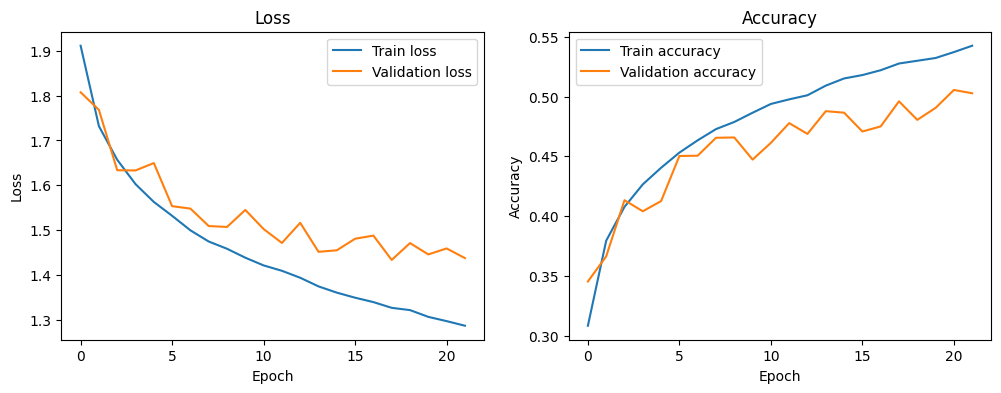

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.show()